# The floor trap: a classifier wrong on every example can score 0.998

On a multiclass problem, several popular measures cannot fall to their nominal minimum,
because each wrong prediction still produces many *true negatives* once the labels are
one-hot encoded. The floor rises with the number of classes. A dashboard that shows
"0.998" is not showing a good model.

This notebook reproduces the effect, shows where it comes from, lists which measures are
affected, and shows how `aggmetrics` warns about it.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q --pre aggmetrics scikit-learn matplotlib pandas

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, hamming_loss, matthews_corrcoef

from aggmetrics import IndicatorMatrix, diagnose, get_measure, list_measures

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## A classifier that is wrong on every example

Ten classes, 500 examples, and a model that predicts the *next* class every time.

In [3]:
m, n = 10, 500
y = np.arange(n) % m          # true class of each example
yhat = (y + 1) % m            # every single prediction is wrong

im = IndicatorMatrix(y, yhat, task="multiclass")
print("accuracy                       :", im.accuracy())
print("label accuracy (micro)         :", im.compute("label_accuracy", "micro"))
print("MCC (micro)                    :", round(im.compute("mcc", "micro"), 4))

accuracy                       : 0.0
label accuracy (micro)         : 0.8
MCC (micro)                    : -0.1111


Accuracy says what it should (0). Label accuracy and MCC do not. The same numbers come
out of `scikit-learn` once the problem is written as an indicator matrix, which is how a
multilabel pipeline or a "per-label" metric sees it:

In [4]:
Y1, P1 = np.eye(m)[y], np.eye(m)[yhat]
print("accuracy_score                 :", accuracy_score(y, yhat))
print("1 - hamming_loss (indicators)  :", 1 - hamming_loss(Y1, P1))
print("matthews_corrcoef (multiclass) :", round(matthews_corrcoef(y, yhat), 4))

accuracy_score                 : 0.0
1 - hamming_loss (indicators)  : 0.8
matthews_corrcoef (multiclass) : -0.1111


## Where the floor comes from

With one-hot labels, each example contributes one entry per class. A wrong prediction gives
one false negative (the true class was missed), one false positive (a wrong class was
predicted) and **`m - 2` true negatives** (every other class correctly left unpredicted).

In [5]:
tp, fp, fn, tn = im.counts
print(f"tp={tp:.0f}  fp={fp:.0f}  fn={fn:.0f}  tn={tn:.0f}   (n={n}, m-2={m-2}, n*(m-2)={n*(m-2)})")

tp=0  fp=500  fn=500  tn=4000   (n=500, m-2=8, n*(m-2)=4000)


Any measure that rewards true negatives is lifted by them: `(tp + tn) / total` is
`(m-2)/m` here, and `m` is the number of classes.

## The floor grows with the number of classes

`attainable_floor(m)` is the value a measure takes when every prediction is wrong. The plot
rescales three measures to the share of their nominal range that a fully wrong classifier
reaches (0 is the worst possible value, 1 the best).

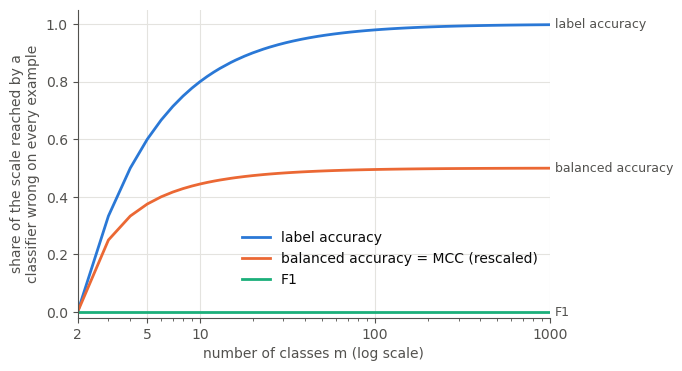

In [6]:
ms = np.unique(np.round(np.logspace(np.log10(2), 3, 60)).astype(int))
nominal = {"label_accuracy": (0, 1), "balanced_accuracy": (0, 1), "mcc": (-1, 1), "f1": (0, 1)}

def share_of_scale(name, m):
    lo, hi = nominal[name]
    return (get_measure(name).attainable_floor(int(m)) - lo) / (hi - lo)

curves = {k: np.array([share_of_scale(k, m) for m in ms]) for k in nominal}
# balanced accuracy and MCC reach exactly the same share of their ranges
assert np.allclose(curves["balanced_accuracy"], curves["mcc"])

fig, ax = plt.subplots(figsize=(7, 4))
for name, color, label in [("label_accuracy", BLUE, "label accuracy"),
                           ("balanced_accuracy", ORANGE, "balanced accuracy = MCC (rescaled)"),
                           ("f1", AQUA, "F1")]:
    ax.plot(ms, curves[name], color=color, label=label)
    ax.text(1000 * 1.06, curves[name][-1], label.split(" =")[0], color=INK2,
            va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xticks([2, 5, 10, 100, 1000])
ax.set_xticklabels(["2", "5", "10", "100", "1000"])
ax.set_xlim(2, 1000)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("number of classes m (log scale)")
ax.set_ylabel("share of the scale reached by a\nclassifier wrong on every example")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.06))
ax.margins(x=0)
fig.subplots_adjust(right=0.8)
plt.show()

With 1000 classes, as in ImageNet, a classifier that is wrong on every single example
still reaches 99.8 % of the scale on label accuracy and half the scale on balanced accuracy.
$F_1$ does not move: it has no true negatives to be lifted by.

## Check the formula against an actual classifier

The closed form should agree with simulating the broken classifier.

In [7]:
rows = []
for m in (10, 1000):
    n = 2 * m
    y = np.arange(n) % m
    im_m = IndicatorMatrix(y, (y + 1) % m, task="multiclass")
    for name in ("label_accuracy", "balanced_accuracy", "mcc", "f1"):
        simulated = im_m.compute(name, "micro")
        formula = get_measure(name).attainable_floor(m)
        assert abs(simulated - formula) < 1e-12
        rows.append((m, name, round(simulated, 4), round(formula, 4)))
pd.DataFrame(rows, columns=["classes", "measure", "simulated", "attainable_floor"])

,classes,measure,simulated,attainable_floor
0,10,label_accuracy,0.8000,0.8000
1,10,balanced_accuracy,0.4444,0.4444
2,10,mcc,-0.1111,-0.1111
3,10,f1,0.0000,0.0000
4,1000,label_accuracy,0.9980,0.9980
5,1000,balanced_accuracy,0.4995,0.4995
6,1000,mcc,-0.0010,-0.0010
7,1000,f1,0.0000,0.0000


## Which measures are affected?

The property is stored with each measure: `tn_dependent_at_zero` is `True` when the value at
`tp = 0` still depends on the true negatives. Lower-is-better measures are affected too, in
the flattering direction: a wrong classifier gets a *low* error rate.

In [8]:
rows = []
for name in list_measures():
    me = get_measure(name)
    rows.append(dict(measure=name,
                     better="higher" if me.greater_is_better else "lower",
                     depends_on_tn_at_tp0=me.tn_dependent_at_zero,
                     value_if_all_wrong_m10=round(me.attainable_floor(10), 4),
                     value_if_all_wrong_m1000=round(me.attainable_floor(1000), 4)))
table = pd.DataFrame(rows).sort_values(["depends_on_tn_at_tp0", "measure"], ascending=[False, True])
table.reset_index(drop=True)

,measure,better,depends_on_tn_at_tp0,value_if_all_wrong_m10,value_if_all_wrong_m1000
0,balanced_accuracy,higher,True,0.4444,0.4995
1,error_rate,lower,True,0.2000,0.0020
2,for,lower,True,0.1111,0.0010
3,fpr,lower,True,0.1111,0.0010
4,informedness,higher,True,-0.1111,-0.0010
5,kappa,higher,True,-0.1111,-0.0010
6,label_accuracy,higher,True,0.8000,0.9980
7,markedness,higher,True,-0.1111,-0.0010
8,mcc,higher,True,-0.1111,-0.0010
9,npv,higher,True,0.8889,0.9990


The measures with `depends_on_tn_at_tp0 = False` (precision, recall, $F_\beta$, Jaccard,
G-mean, Fowlkes–Mallows) reach their nominal worst value, so they are safe to read on a
many-class problem. The others are not wrong; they need a floor next to them.

## Let the library warn you

`diagnose` returns structured findings. The first one below is the floor warning.

In [9]:
im = IndicatorMatrix(np.arange(500) % 10, (np.arange(500) + 1) % 10, task="multiclass")
findings = diagnose(im)
print(f"{len(findings)} findings; codes:", sorted({f.code for f in findings}))
print()
print(next(f for f in findings if f.code == "inflated_floor"))

8 findings; codes: ['degenerate_optimum', 'inflated_floor', 'micro_collapse', 'ovr_skew_drift']

[warning] inflated_floor: 'balanced_accuracy' cannot fall below 0.4444 on this 10-class one-hot problem even if every prediction is wrong, because a misclassified example still contributes 8 true negatives.


In a test suite or CI job, `emit_warnings=True` turns each warning-level finding into a
Python warning (`MeasureWarning`), so an evaluation script can be made to fail on a flawed
protocol:

In [10]:
import warnings
from aggmetrics.diagnostics import MeasureWarning

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    diagnose(im, emit_warnings=True)
print(len(caught), "warnings raised; all MeasureWarning:",
      all(issubclass(w.category, MeasureWarning) for w in caught))

6 warnings raised; all MeasureWarning: True


## What to report instead

- On a many-class problem, report $F_1$ or recall (per class, then macro), which have no
  true-negative floor, or report a measure *together with its floor*.
- Do not read a high label accuracy, balanced accuracy or MCC on a problem with many
  classes as evidence of a good model without checking `attainable_floor`.
- Keep `diagnose` in the evaluation script: it states the floor for the measures you report.

Next: *02 Micro, macro and imbalance*.